
# Stage-detection sensors over each run of consecutive days

The logger data is not one unbroken series. Recording happened in **runs**: blocks of back-to-back day files with long
breaks in between. This notebook draws each run as one continuous time series, so a heat-up or hold that crosses
midnight is seen in one piece and nothing is drawn across a break.

Only the sensors that the stage detection (`operating_states.load_signals`) reads are shown. They come from the
stage-sensor export of `preprocessing.ipynb` (`../02_data/preprocessed_stage/`, 10 s means):

| Panel | Sensor | Used by the stage rules for |
|---|---|---|
| Stack temperature | `TIR_4_6_*` (35 thermocouples; `TIR_4_6_19` is stuck and was dropped; `TIR_4_6_25` reads ambient and is drawn dotted, outside the median) | stack temperature, its rate of change, the 450 / 550 °C bands |
| Cathode inlet | `TIRC_2_06` | EAPH outlet / cathode inlet temperature |
| Ambient proxy | `TIR_1_1_1`, `TIR_1_2_1`, `TIR_1_3`, `TIR_1_4_1` | room temperature for the Shut-down "at ambient" rule |
| Air | `PIR_2_02` | air on (> 1.0) |
| EAPH heater | `EIRC_2_01_ActV_In_ThreePhasePower` | heater on (> 200 W) |
| String loads | `rCurrMonitor`, `rVoltMonitor` per string, power = V × I | load on (> 1 A per string), part load |

The bottom strip shows the stage label of each minute (`04_synthetic_data/library/traces_1min.parquet`,
produced from `operating_states.py`). Grey vertical lines mark midnight; dashed grey lines are the thresholds the stage rules use.


In [1]:

import json
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import sys
sys.path.insert(0, "scripts")   # helper modules live in 03_data_analysis/scripts/
import operating_states as ops

PRE = Path("../02_data/preprocessed_stage")                  # stage-sensor export, 10 s
GROUPS = Path("preprocessing/stage/column_groups.json")
STAGES = Path("../04_synthetic_data/library/traces_1min.parquet")
RULE = "1min"                                                  # plotting resolution

groups = json.loads(GROUPS.read_text())
TC = groups["TIR_4"]                                           # stack thermocouples
TC_MEDIAN = [c for c in TC if c != "TIR_4_6_25"]               # TIR_4_6_25 reads ambient whatever the stack does
AMB = groups["TIR_1"]
STRINGS = range(1, 6)
I_COLS = [f"PLC_hostSetp_ctrl_ctEIRC4{s}_rCurrMonitor" for s in STRINGS]
V_COLS = [f"PLC_hostSetp_ctrl_ctEIRC4{s}_rVoltMonitor" for s in STRINGS]
P_COLS = [f"EIRC_4{s}_Power_kW" for s in STRINGS]
EAPH = "EIRC_2_01_ActV_In_ThreePhasePower"

# Fixed colour per string / probe (validated categorical palette, colour-blind safe); stages keep the project colours
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
INK, MUTED, GRID = "#1f1f1e", "#8a8984", "#d9d8d3"

stage_min = pd.read_parquet(STAGES, columns=["stage"])["stage"] if STAGES.exists() else None

days = sorted(p.stem for p in PRE.glob("*.parquet"))
day_dates = pd.to_datetime(days, format="%Y%m%d")
run_id = (pd.Series(day_dates).diff() != pd.Timedelta(days=1)).cumsum() - 1
runs = (pd.DataFrame({"day": day_dates, "run": run_id.values})
        .groupby("run")["day"].agg(start="first", end="last", days="count"))
runs


,start,end,days
run,,,
0,2025-10-30,2025-10-30,1
1,2025-11-13,2025-11-18,6
2,2026-01-30,2026-02-06,8
3,2026-02-13,2026-02-18,6
4,2026-03-01,2026-03-04,4
5,2026-03-12,2026-03-13,2
6,2026-03-17,2026-03-20,4
7,2026-03-22,2026-03-26,5
8,2026-03-28,2026-03-30,3



## Plot functions

`plot_run(run)` draws one run; `plot_window(start, end)` draws any time window (it may span several days of one run).


In [2]:

def fmt(d):
    return pd.Timestamp(d).strftime("%d %b %Y")


def run_label(run):
    r = runs.loc[run]
    return fmt(r["start"]) if r["days"] == 1 else f"{fmt(r['start'])} - {fmt(r['end'])} ({r['days']} days)"


def load(start, end, rule=RULE):
    """Stage sensors between two dates (inclusive days), resampled to `rule`."""
    parts = [pd.read_parquet(PRE / f"{d:%Y%m%d}.parquet")
             for d in pd.date_range(pd.Timestamp(start).normalize(), pd.Timestamp(end).normalize())
             if (PRE / f"{d:%Y%m%d}.parquet").exists()]
    df = pd.concat(parts).sort_index()
    return df.resample(rule).mean() if rule else df


def stack_median(df):
    t = df[TC_MEDIAN].where(lambda v: (v > 0) & (v < 1000))
    return t.median(axis=1)


def _threshold(ax, y, text):
    ax.axhline(y, color=MUTED, lw=0.8, ls="--", zorder=1)
    ax.annotate(text, (1, y), xycoords=("axes fraction", "data"), xytext=(-4, 2), textcoords="offset points",
                ha="right", va="bottom", fontsize=7, color=MUTED,
                bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none", alpha=0.85))


def _lines(ax, df, cols, labels):
    for c, lab, col in zip(cols, labels, SERIES):
        ax.plot(df.index, df[c], color=col, lw=1, label=lab)
    ax.legend(fontsize=7, ncol=len(cols), loc="upper left", frameon=False)


def plot_sensors(df, title):
    panels = [("Stack T [°C]", 2.2), ("Cathode inlet [°C]", 1.1), ("Ambient proxy [°C]", 1.1), ("Air PIR_2_02", 1),
              ("EAPH power [kW]", 1), ("String current [A]", 1.2), ("String voltage [V]", 1.1),
              ("String power [kW]", 1.1), ("Stage", 0.35)]
    fig, ax = plt.subplots(len(panels), 1, figsize=(15, 17), sharex=True,
                           gridspec_kw={"height_ratios": [h for _, h in panels], "hspace": 0.12})
    fig.subplots_adjust(top=0.965, bottom=0.05)

    # Stack thermocouples: every TC thin, median bold
    tcs = df[TC_MEDIAN].where(lambda v: (v > 0) & (v < 1000))
    ax[0].plot(tcs.index, tcs.values, color="#c3c2b7", lw=0.5)
    ax[0].plot(df.index, stack_median(df), color=INK, lw=1.6, label="median of the stack thermocouples")
    ax[0].plot([], [], color="#c3c2b7", lw=1, label=f"each of {len(TC_MEDIAN)} thermocouples (TIR_4_6_*)")
    ax[0].plot(df.index, df["TIR_4_6_25"].where(lambda v: (v > 0) & (v < 1000)), color=MUTED, lw=0.8, ls=":",
               label="TIR_4_6_25 (reads ambient, left out of the median)")
    ax[0].legend(fontsize=7, loc="upper left", frameon=False)
    _threshold(ax[0], ops.T_HOT, f"{ops.T_HOT:.0f} °C: Hot standby lower bound")
    _threshold(ax[0], ops.T_STANDBY, f"{ops.T_STANDBY:.0f} °C: intermediate hold upper bound")

    ax[1].plot(df.index, df["TIRC_2_06"], color=INK, lw=1, label="TIRC_2_06")
    ax[1].legend(fontsize=7, loc="upper left", frameon=False)

    amb = df[AMB].where(lambda v: (v != -1) & (v < 60))
    _lines(ax[2], amb, AMB, AMB)

    ax[3].plot(df.index, df["PIR_2_02"], color=INK, lw=1, label="PIR_2_02 (as logged)")
    ax[3].legend(fontsize=7, loc="upper left", frameon=False)
    _threshold(ax[3], ops.AIR_ON, f"{ops.AIR_ON:g}: air on")

    ax[4].plot(df.index, df[EAPH] / 1000, color=INK, lw=1, label="EIRC2.01 three-phase power")
    ax[4].legend(fontsize=7, loc="upper left", frameon=False)
    _threshold(ax[4], ops.EAPH_ON_W / 1000, f"{ops.EAPH_ON_W:.0f} W: heater on")

    names = [f"string {s}" for s in STRINGS]
    _lines(ax[5], df, I_COLS, names)
    _threshold(ax[5], ops.I_LOAD, f"{ops.I_LOAD:g} A: load on")
    _lines(ax[6], df, V_COLS, names)
    _lines(ax[7], df, P_COLS, names)

    # Stage strip
    st = None if stage_min is None else stage_min.reindex(pd.date_range(df.index.min(), df.index.max(), freq="1min"))
    if st is not None and st.notna().any():
        block = (st != st.shift()).cumsum()
        for _, b in st.groupby(block):
            if pd.notna(b.iloc[0]):
                ax[8].axvspan(b.index[0], b.index[-1] + pd.Timedelta(minutes=1),
                              color=ops.STAGE_COLORS.get(b.iloc[0], "#ffffff"), lw=0)
        seen = [s for s in ops.STAGES if s in set(st.dropna())]
        ax[8].legend([plt.Rectangle((0, 0), 1, 1, color=ops.STAGE_COLORS[s]) for s in seen], seen,
                     fontsize=7, ncol=len(seen), loc="upper center", bbox_to_anchor=(0.5, -0.9), frameon=False)
    else:
        ax[8].text(0.5, 0.5, "no stage labels for this window", transform=ax[8].transAxes,
                   ha="center", va="center", fontsize=8, color=MUTED)
    ax[8].set_yticks([])

    midnights = pd.date_range(df.index.min().ceil("D"), df.index.max(), freq="D")
    for a, (name, _) in zip(ax, panels):
        a.set_ylabel(name, fontsize=8, rotation=0, ha="right", va="center")
        a.tick_params(labelsize=7, colors=INK)
        a.grid(axis="y", color=GRID, lw=0.5)
        for spine in ("top", "right"):
            a.spines[spine].set_visible(False)
        for m in midnights:
            a.axvline(m, color=GRID, lw=0.8, zorder=0)
    span = df.index.max() - df.index.min()
    ax[-1].xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 3)) if span <= pd.Timedelta(days=1)
                                   else mdates.DayLocator())
    ax[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M" if span <= pd.Timedelta(days=1) else "%d %b"))
    ax[-1].set_xlim(df.index.min(), df.index.max())
    fig.suptitle(title, x=0.125, ha="left", y=0.985, fontsize=12, color=INK)
    plt.show()


def stage_hours(start, end):
    """Hours per stage between start and end (from the 1-min stage labels)."""
    if stage_min is None:
        return None
    s = stage_min[(stage_min.index >= pd.Timestamp(start)) & (stage_min.index < pd.Timestamp(end))]
    h = (s.value_counts() / 60).reindex([x for x in ops.STAGES if x in set(s)]).round(1)
    return h.rename("hours").to_frame().T


def plot_run(run):
    r = runs.loc[run]
    df = load(r["start"], r["end"])
    plot_sensors(df, f"Run {run}: {run_label(run)}")
    return stage_hours(r["start"], r["end"] + pd.Timedelta(days=1))


def plot_window(start, end, rule=RULE):
    """Any time window, e.g. plot_window("2026-03-23 06:00", "2026-03-24 12:00")."""
    df = load(start, end, rule).loc[start:end]
    plot_sensors(df, f"{pd.Timestamp(start):%d %b %Y %H:%M} - {pd.Timestamp(end):%d %b %Y %H:%M}")
    return stage_hours(start, end)


## Run 0: 30 Oct 2025

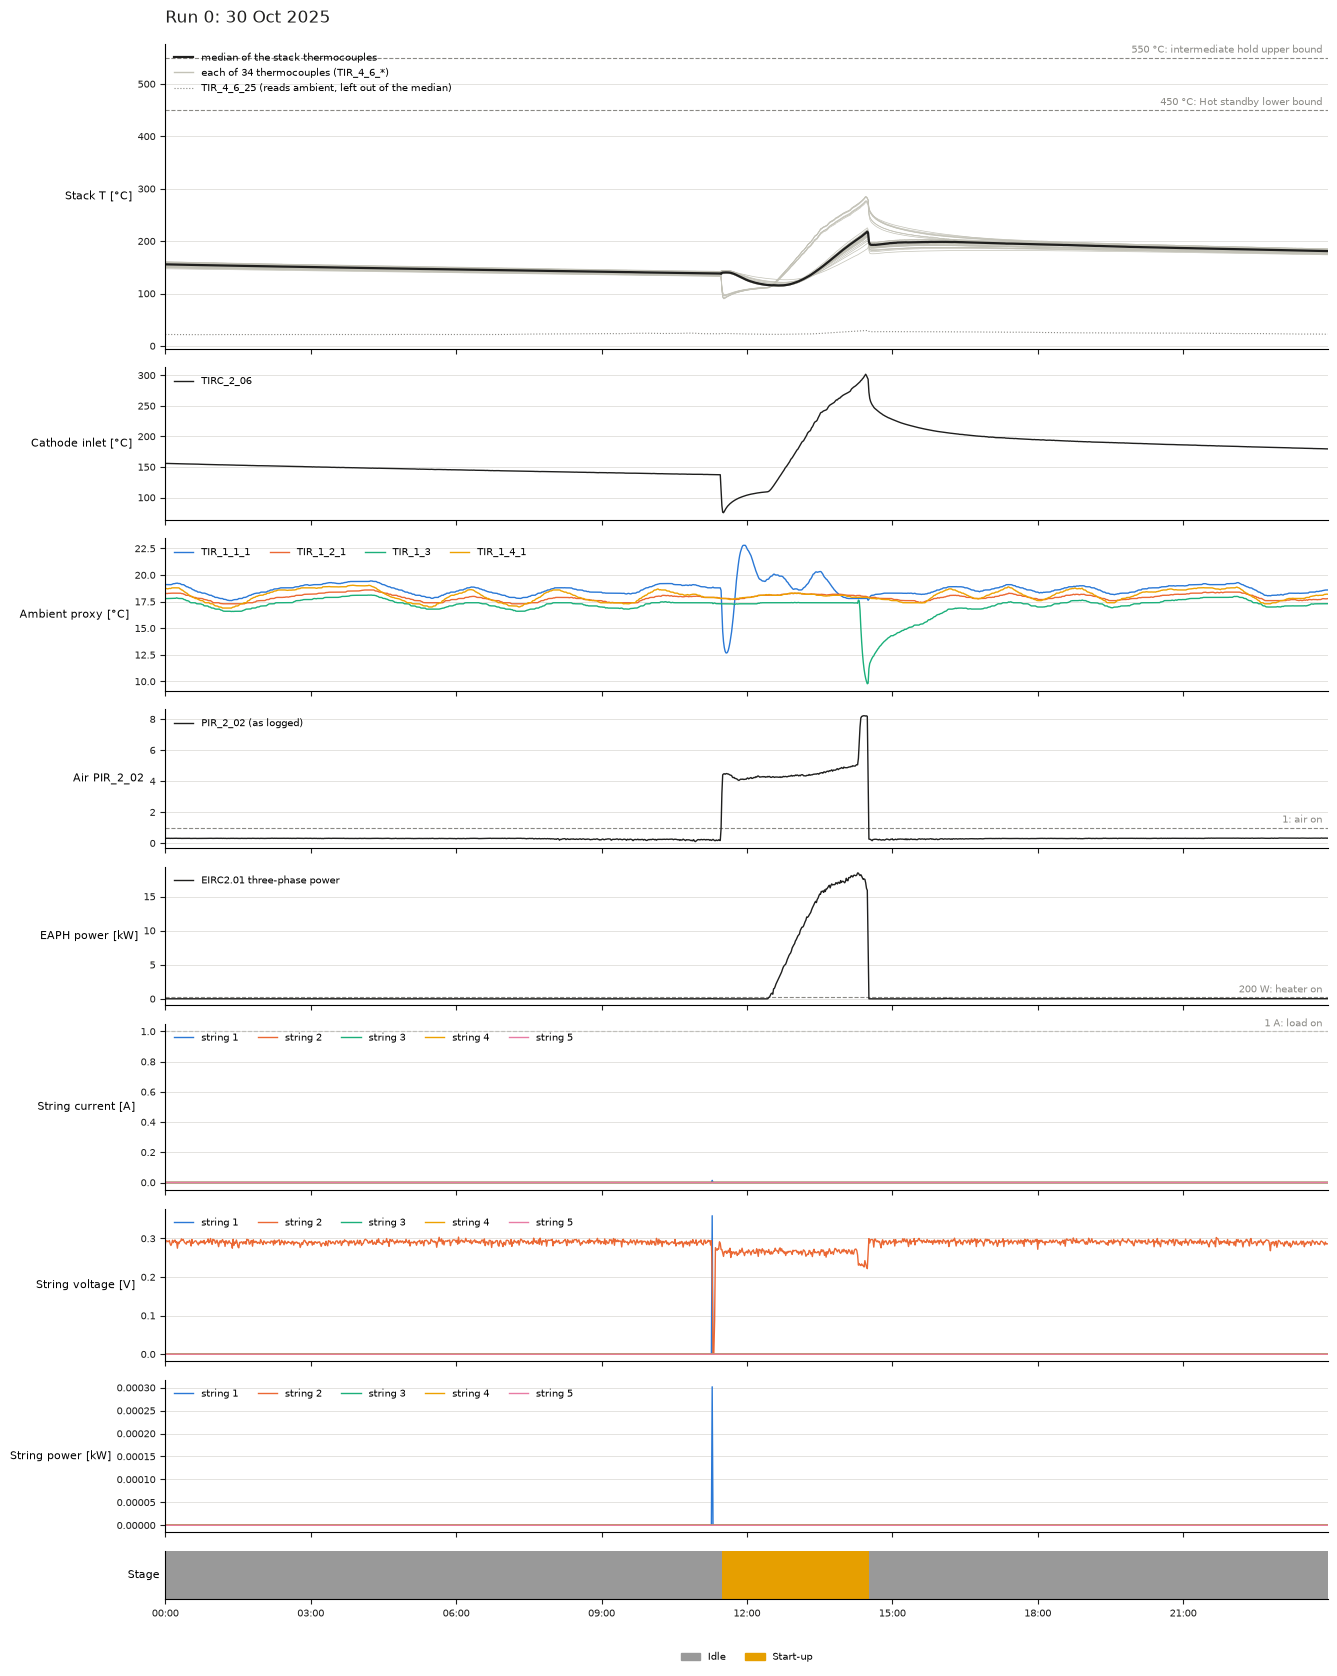

stage,Idle,Start-up
hours,21.0,3.0


In [3]:
plot_run(0)

## Run 1: 13 Nov 2025 - 18 Nov 2025 (6 days)

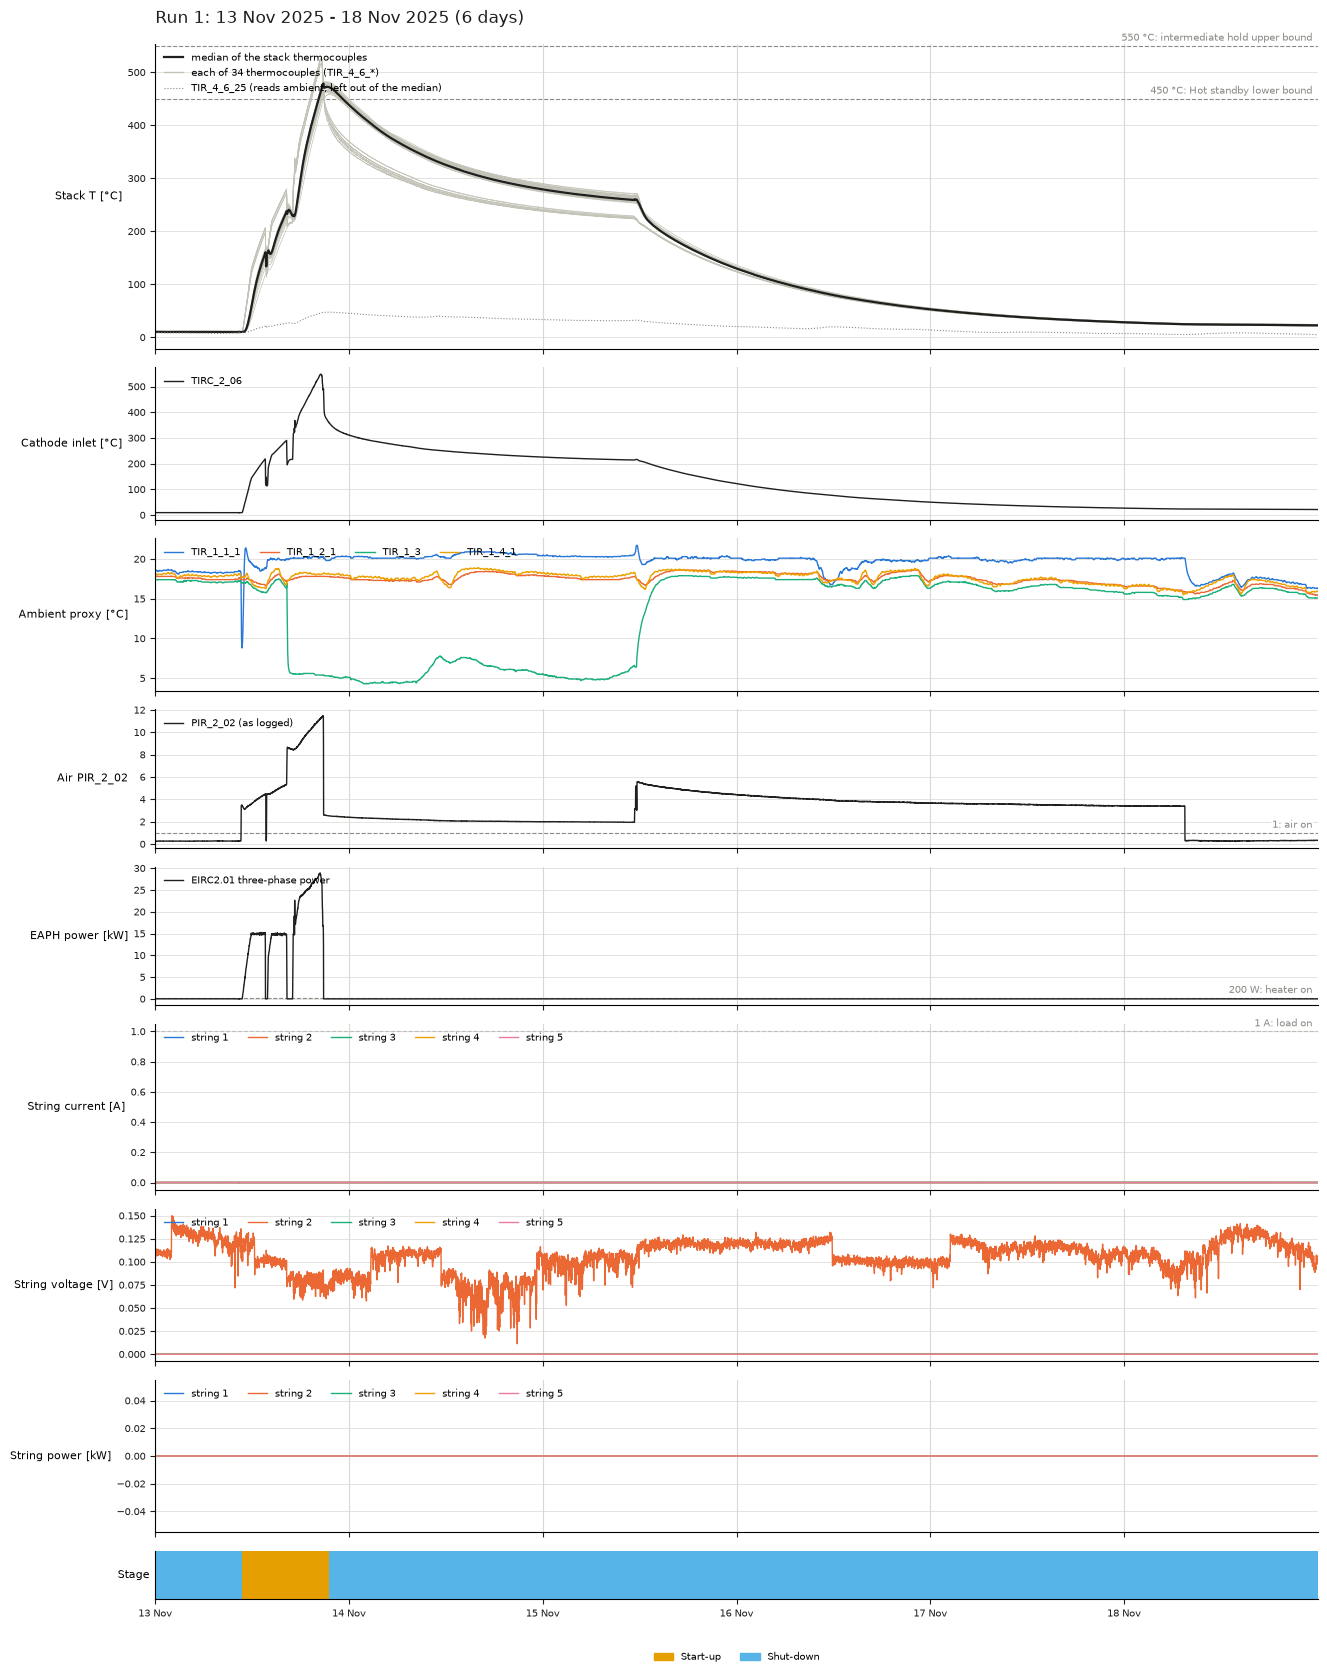

stage,Start-up,Shut-down
hours,10.8,133.2


In [4]:
plot_run(1)

## Run 2: 30 Jan 2026 - 06 Feb 2026 (8 days)

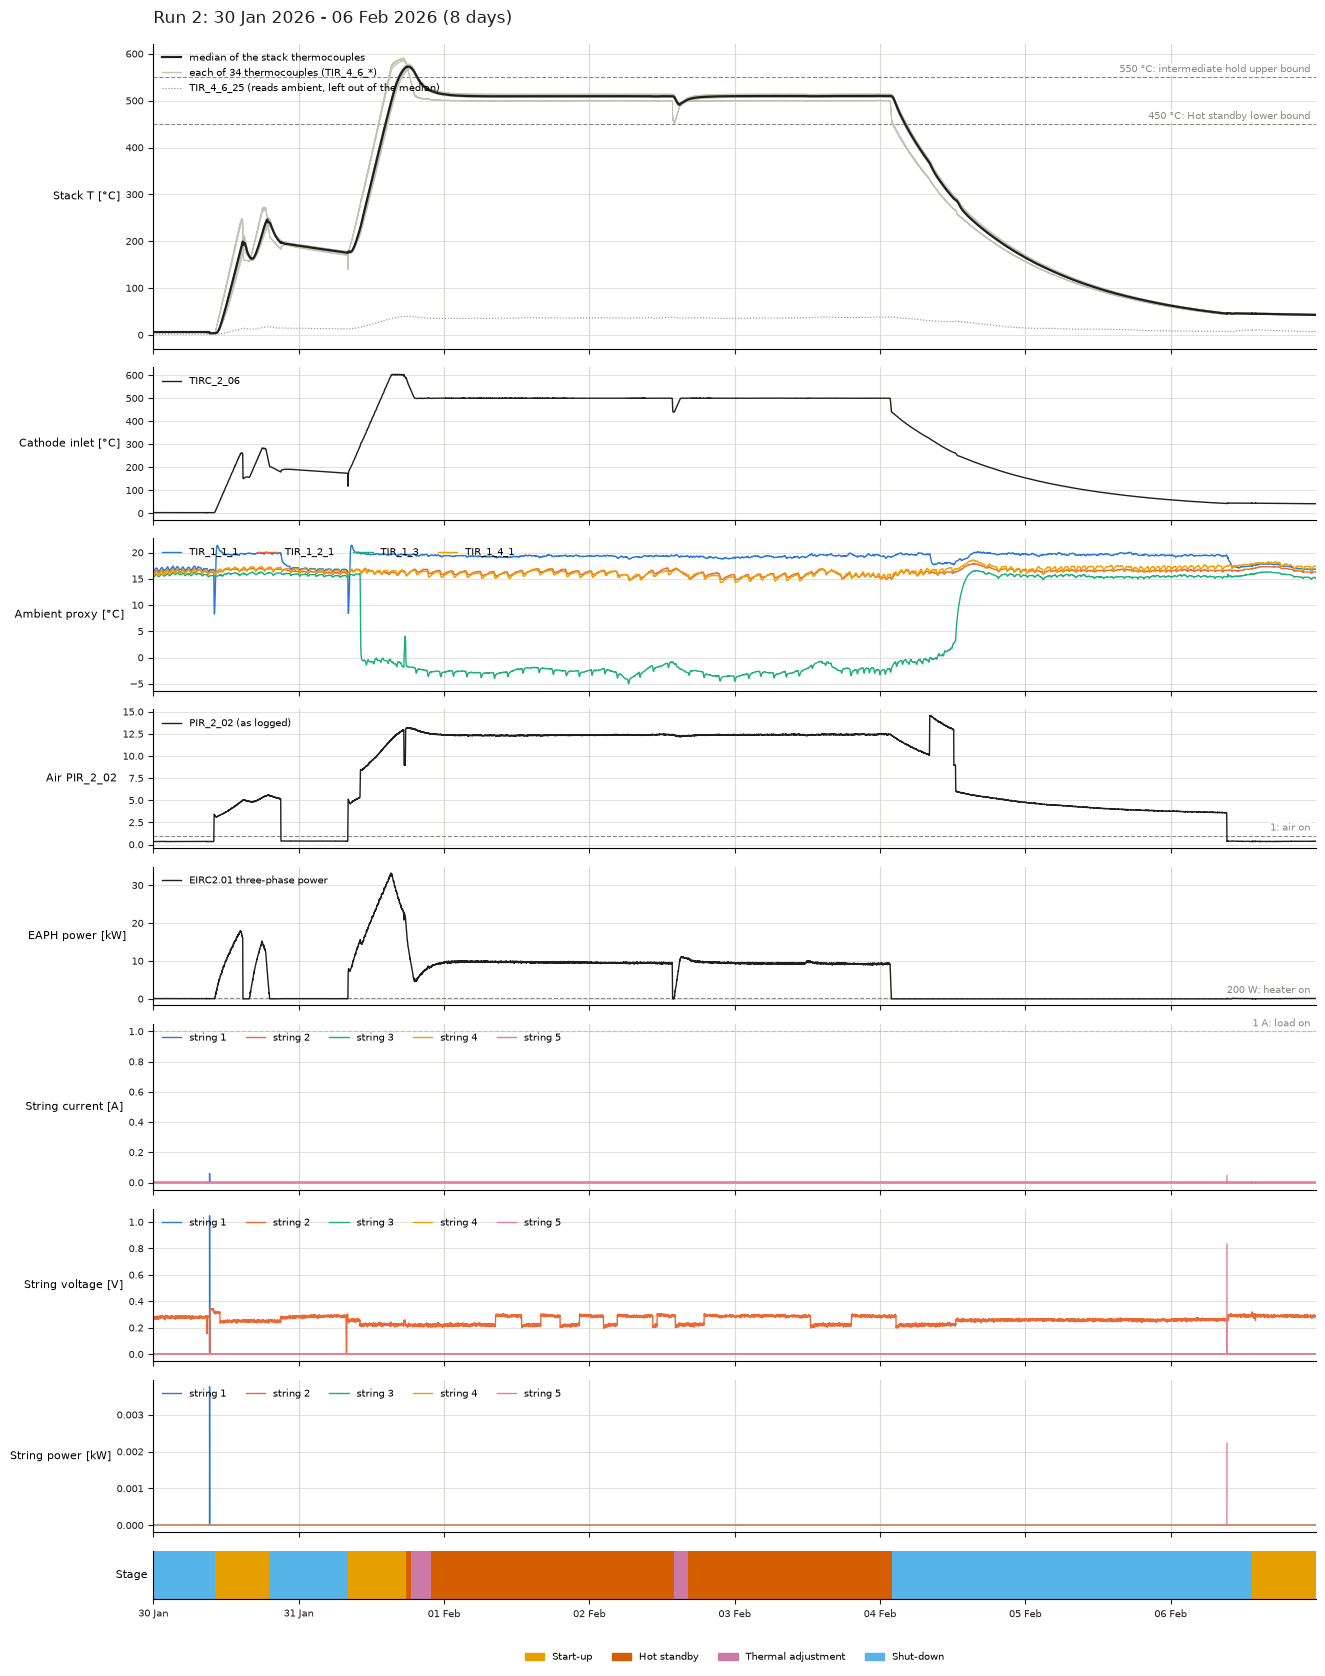

stage,Start-up,Hot standby,Thermal adjustment,Shut-down
hours,29.2,74.4,5.8,82.6


In [5]:
plot_run(2)

## Run 3: 13 Feb 2026 - 18 Feb 2026 (6 days)

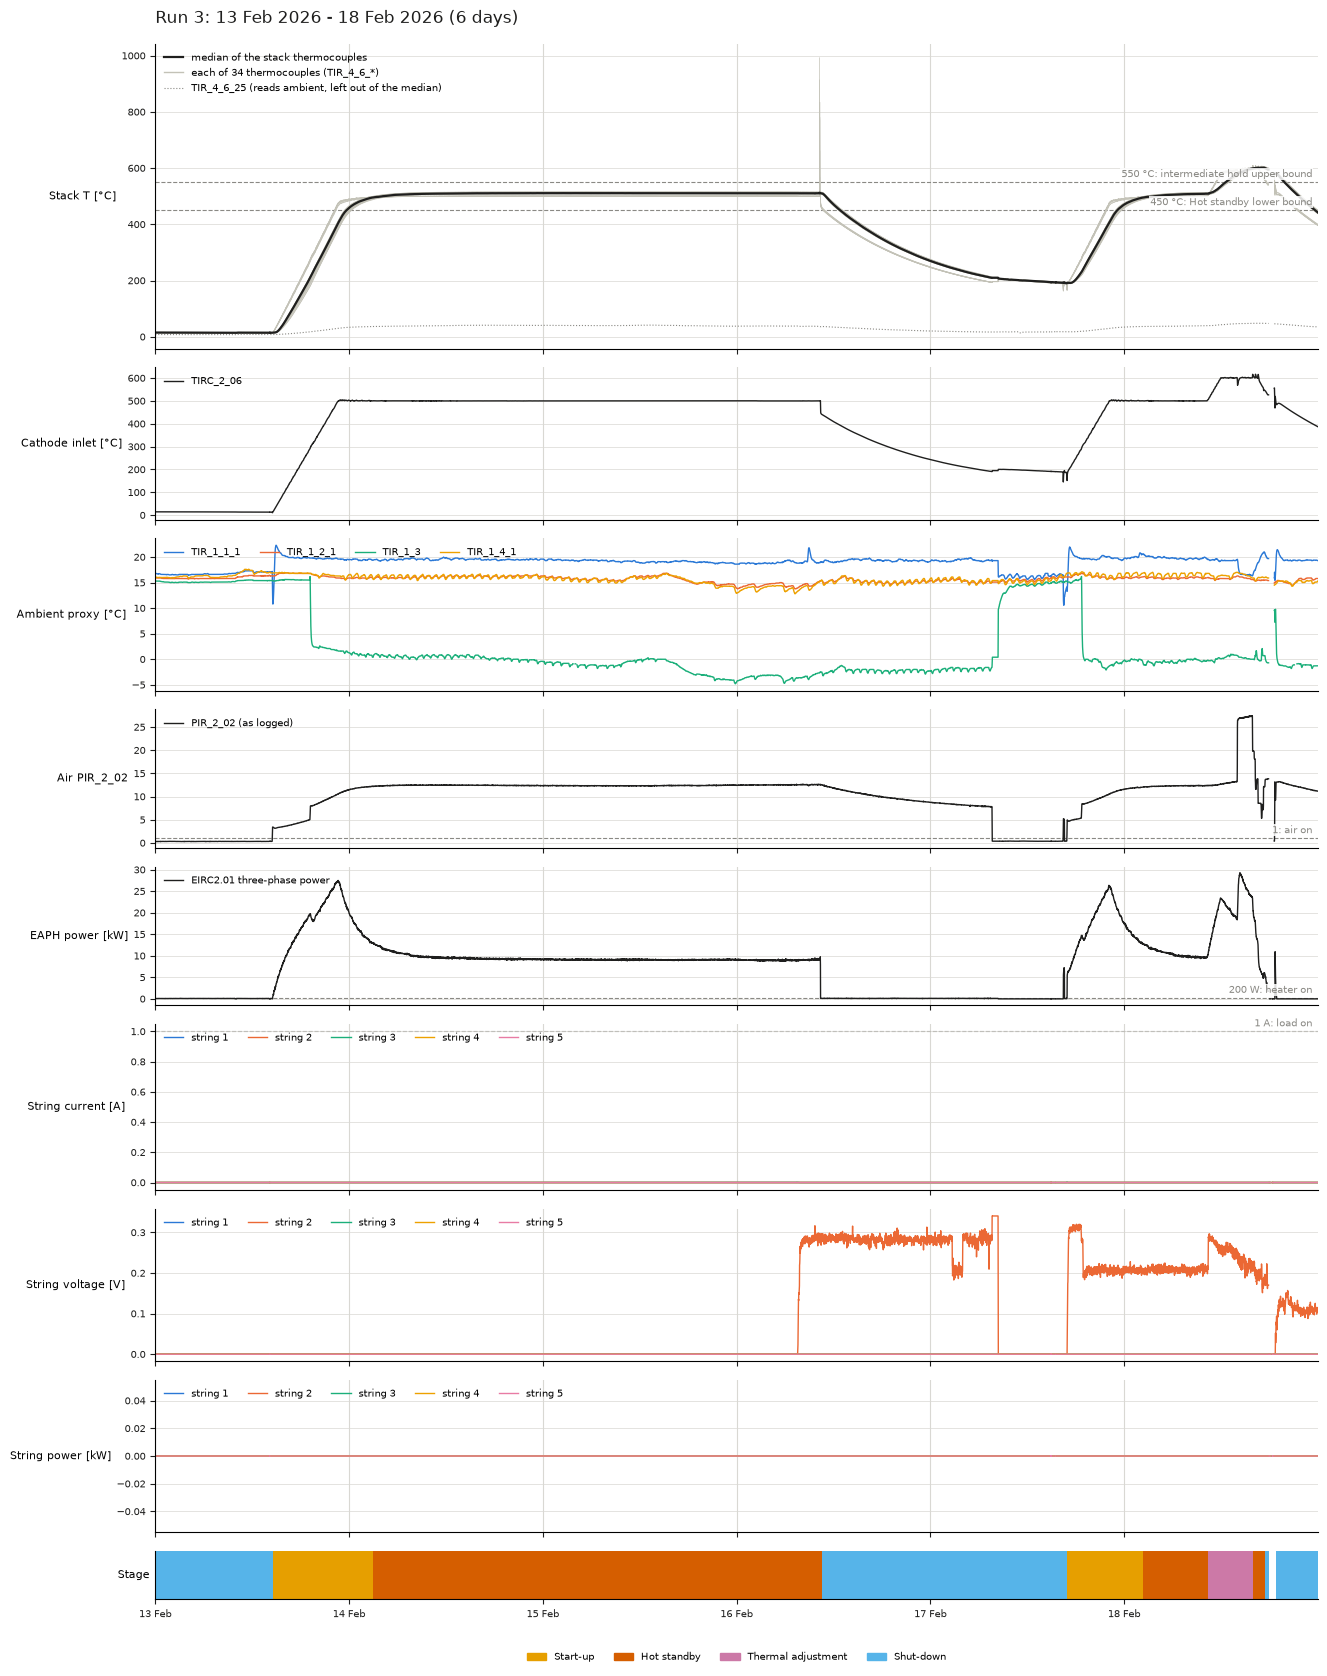

stage,Start-up,Hot standby,Thermal adjustment,Shut-down
hours,21.8,65.2,5.6,50.4


In [6]:
plot_run(3)

## Run 4: 01 Mar 2026 - 04 Mar 2026 (4 days)

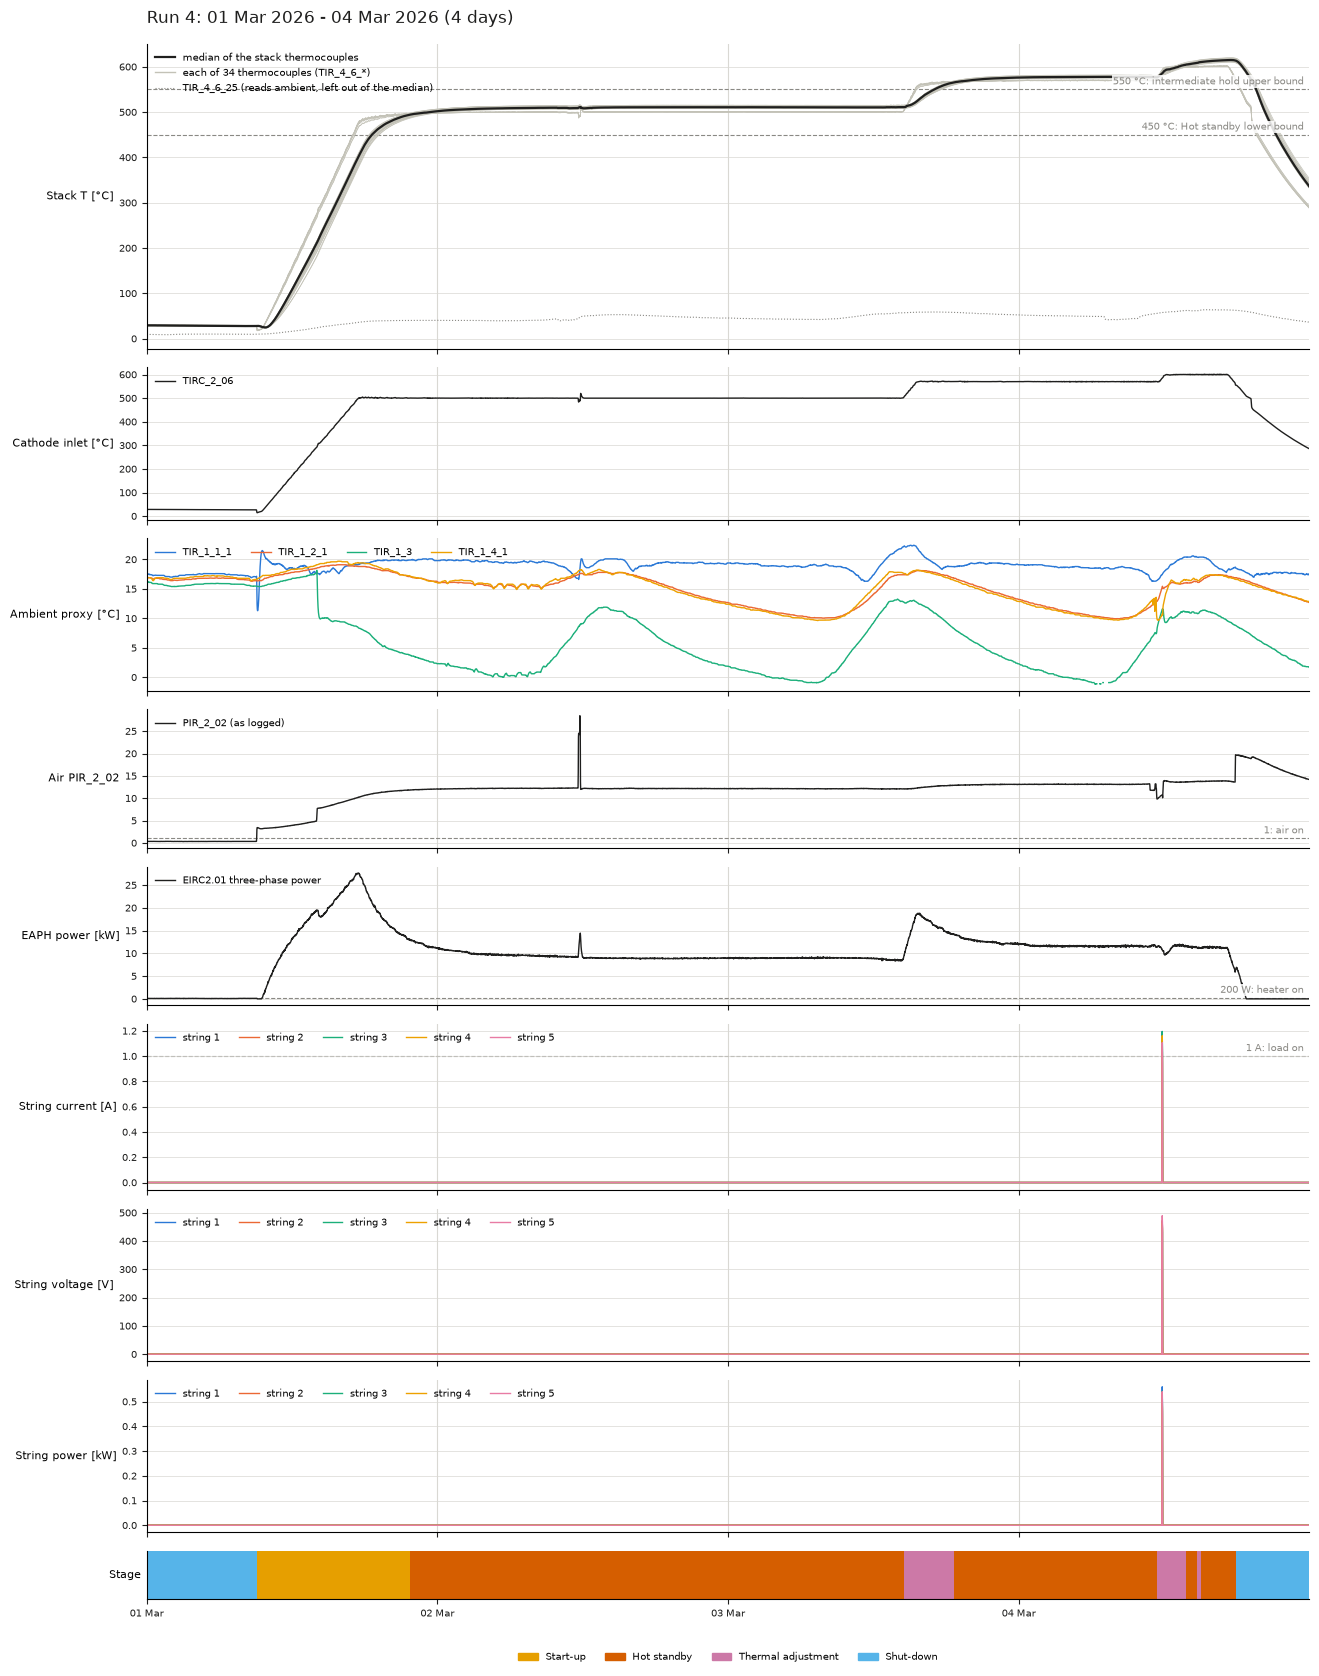

stage,Start-up,Hot standby,Thermal adjustment,Shut-down
hours,12.6,61.4,6.8,15.2


In [7]:
plot_run(4)

## Run 5: 12 Mar 2026 - 13 Mar 2026 (2 days)

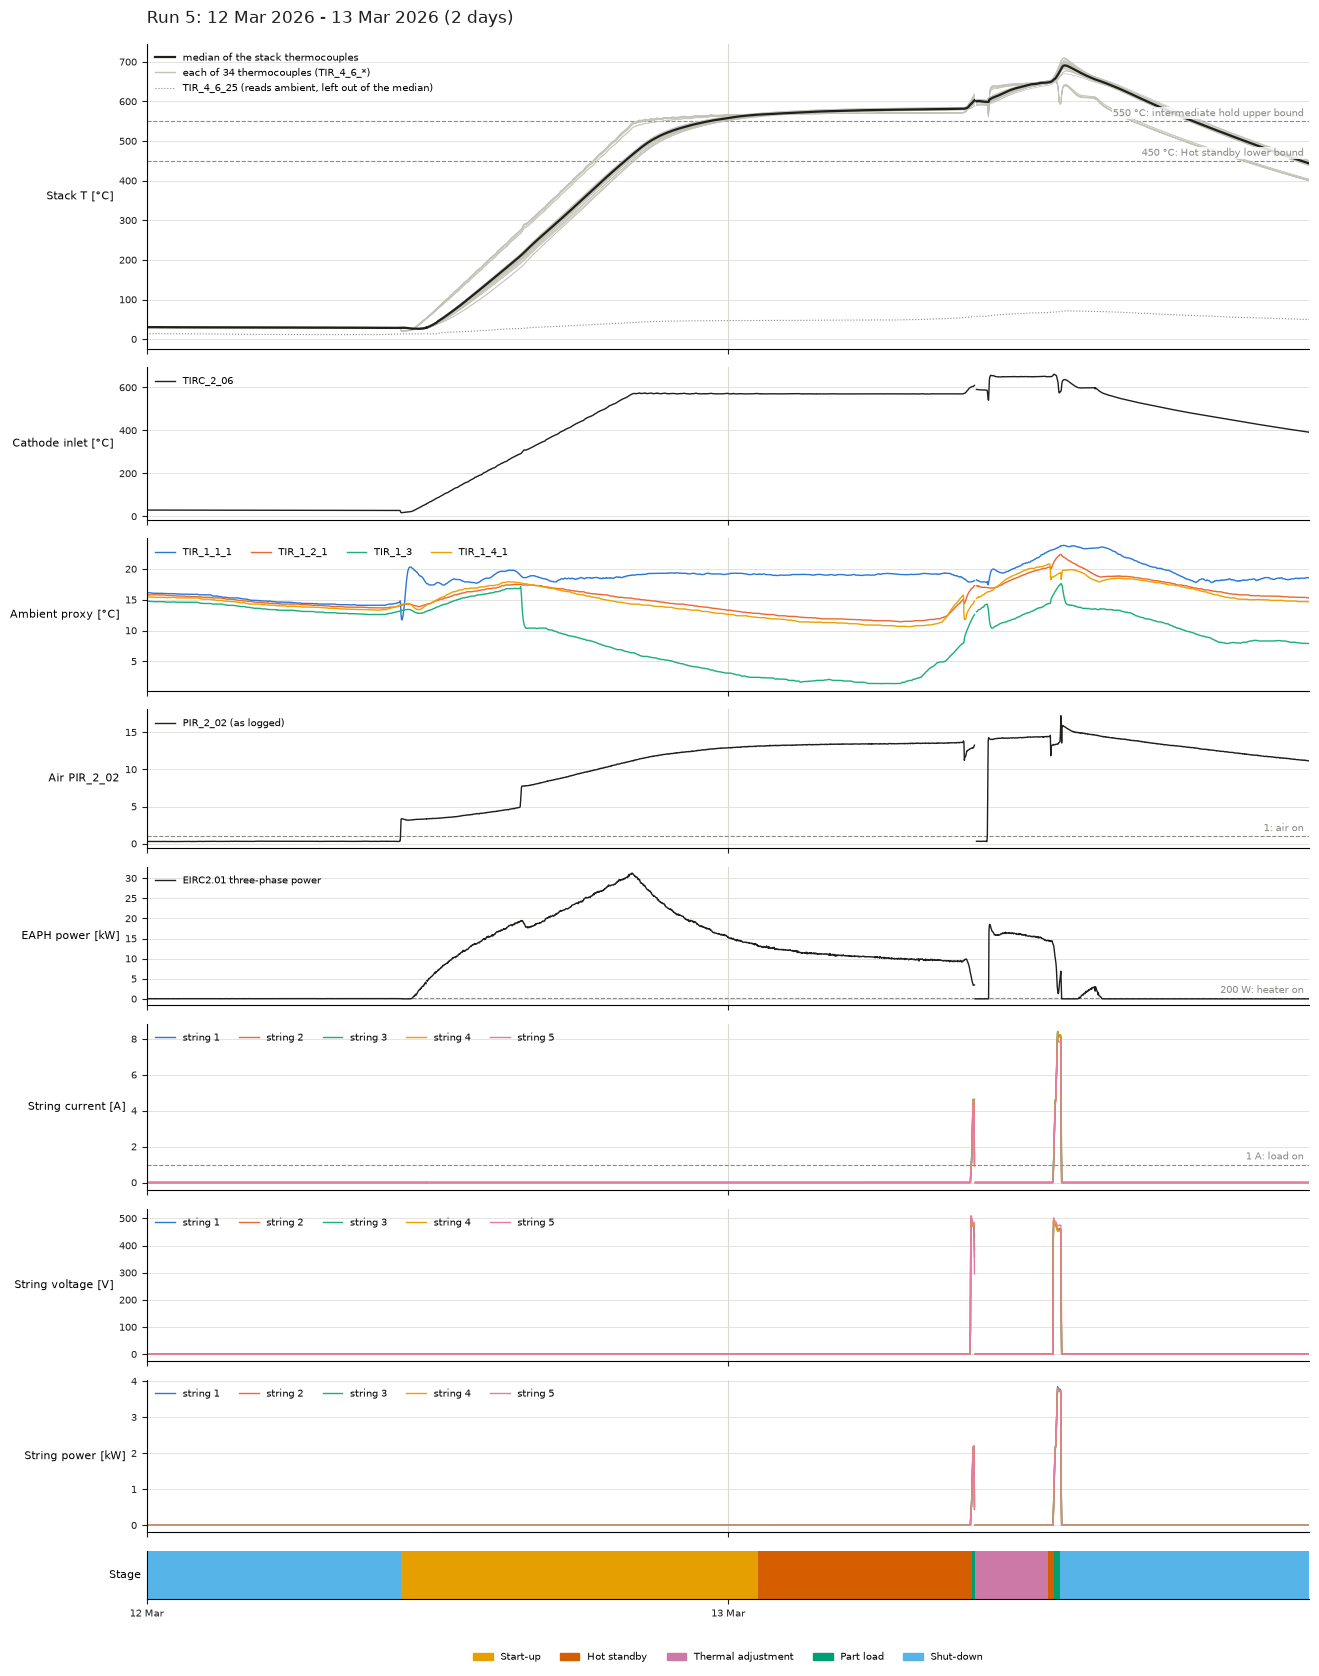

stage,Start-up,Hot standby,Thermal adjustment,Part load,Shut-down
hours,14.7,9.1,3.0,0.4,20.8


In [8]:
plot_run(5)

## Run 6: 17 Mar 2026 - 20 Mar 2026 (4 days)

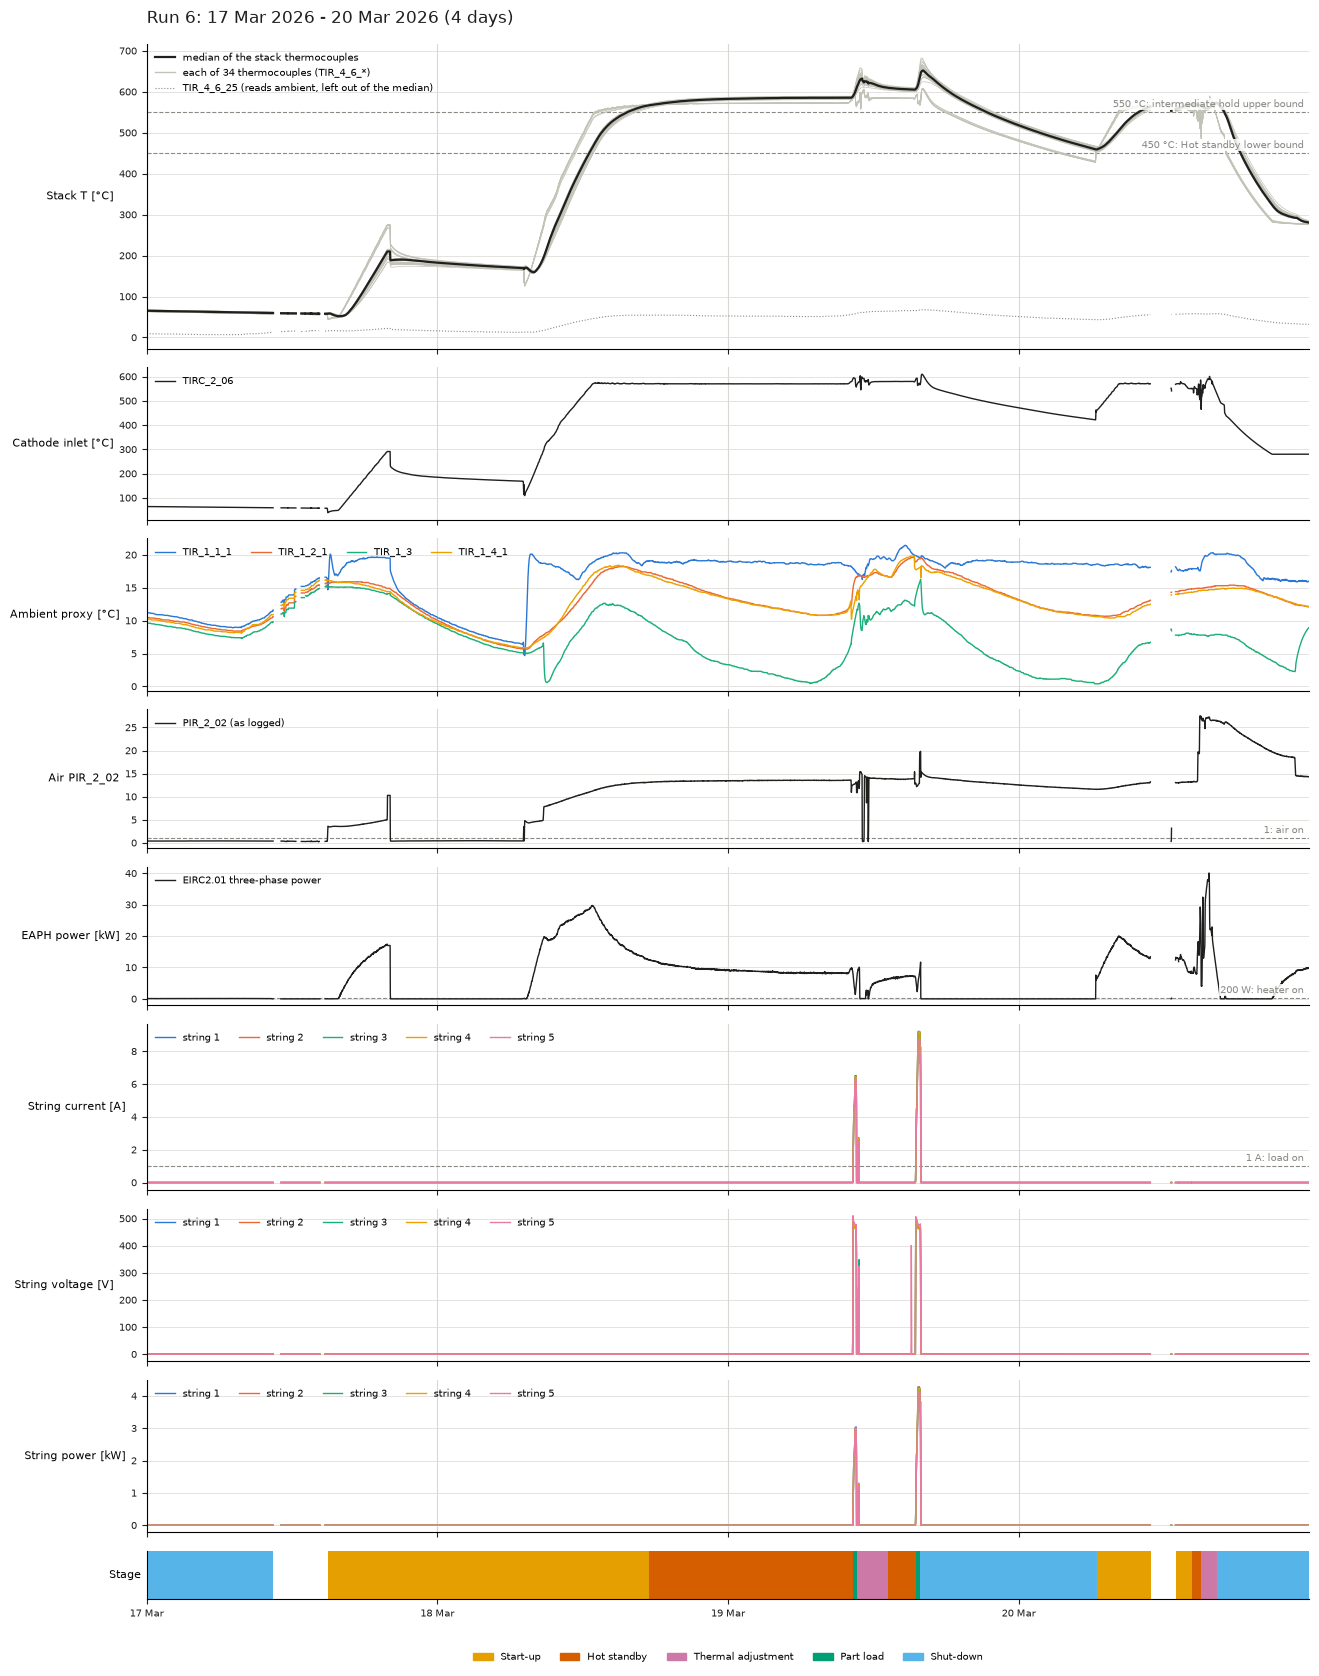

stage,Start-up,Hot standby,Thermal adjustment,Part load,Shut-down
hours,32.2,19.9,4.0,0.6,32.7


In [9]:
plot_run(6)

## Run 7: 22 Mar 2026 - 26 Mar 2026 (5 days)

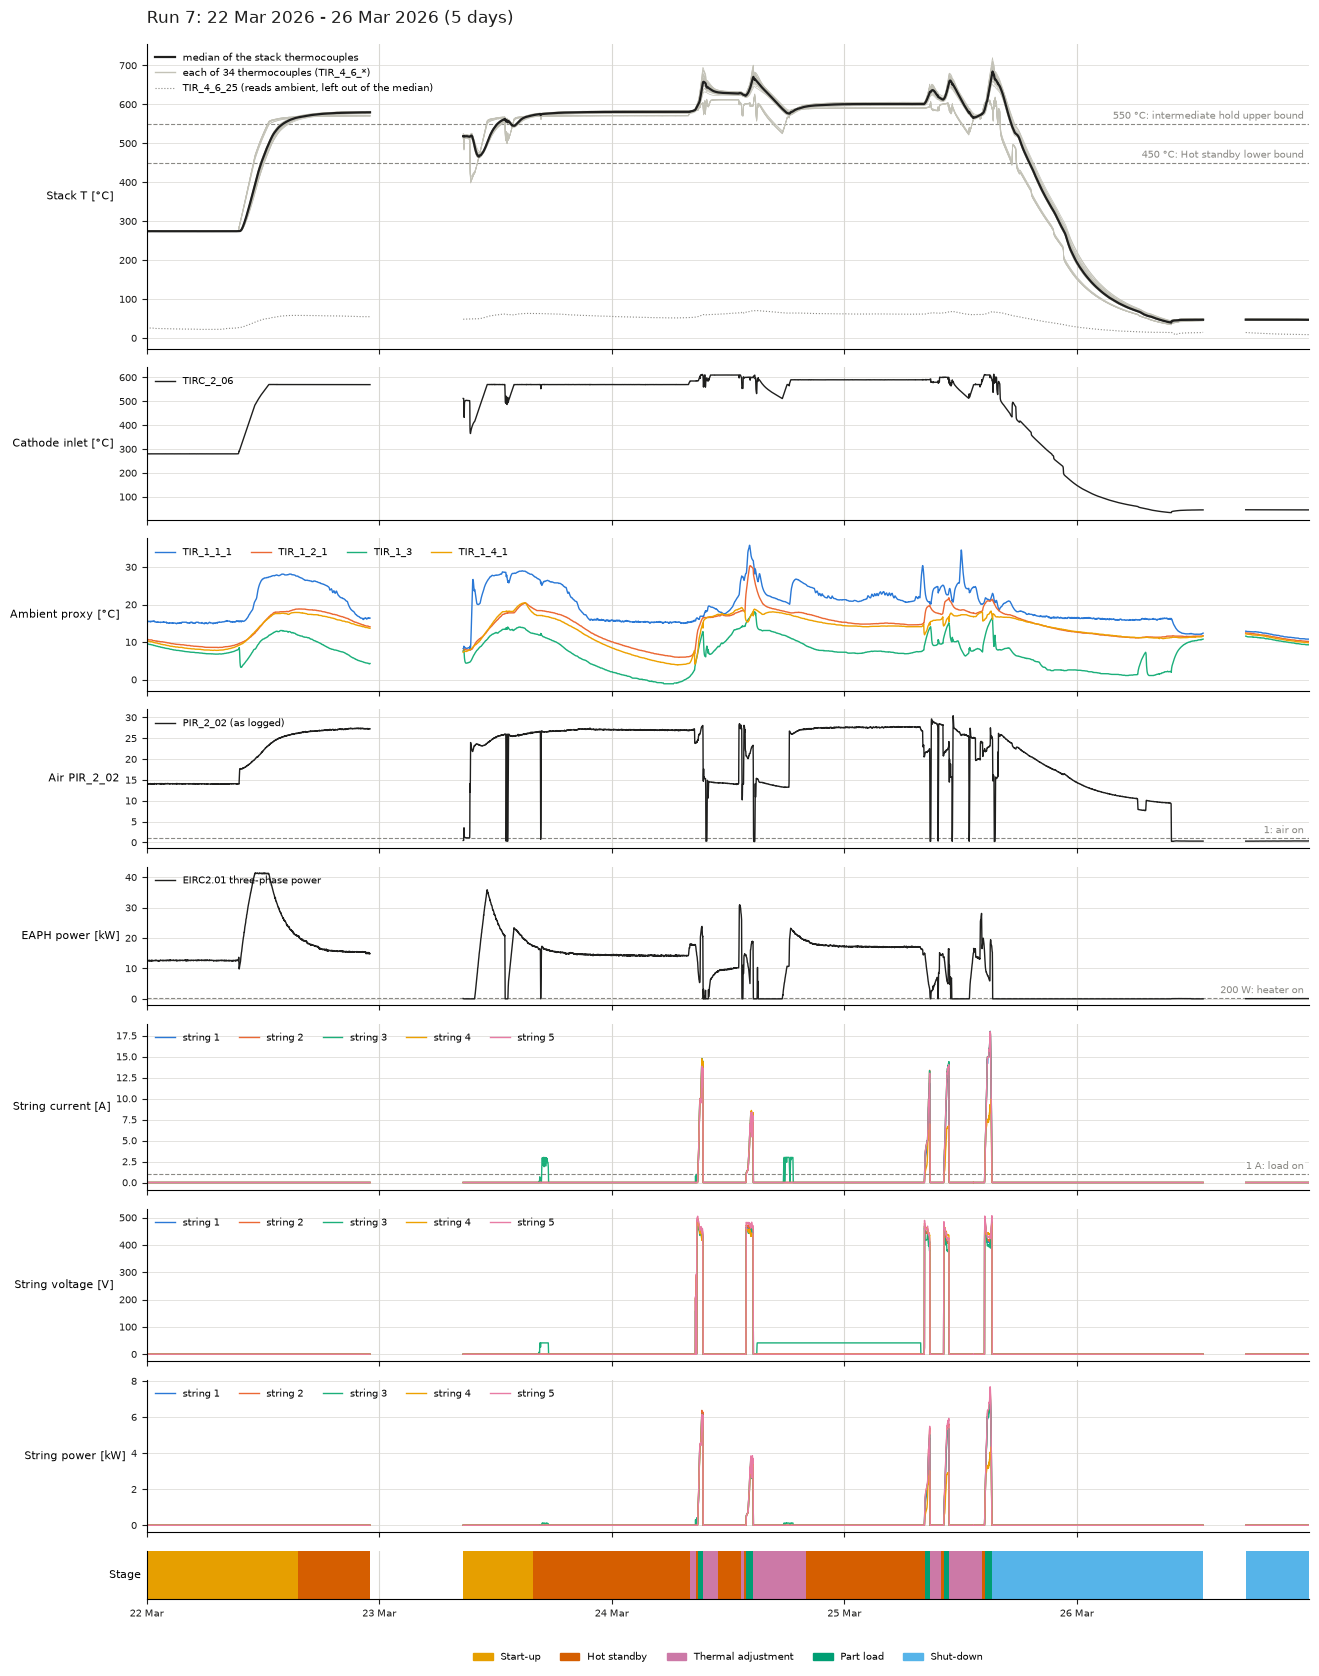

stage,Start-up,Hot standby,Thermal adjustment,Part load,Shut-down
hours,22.8,39.4,12.3,3.1,28.4


In [10]:
plot_run(7)

## Run 8: 28 Mar 2026 - 30 Mar 2026 (3 days)

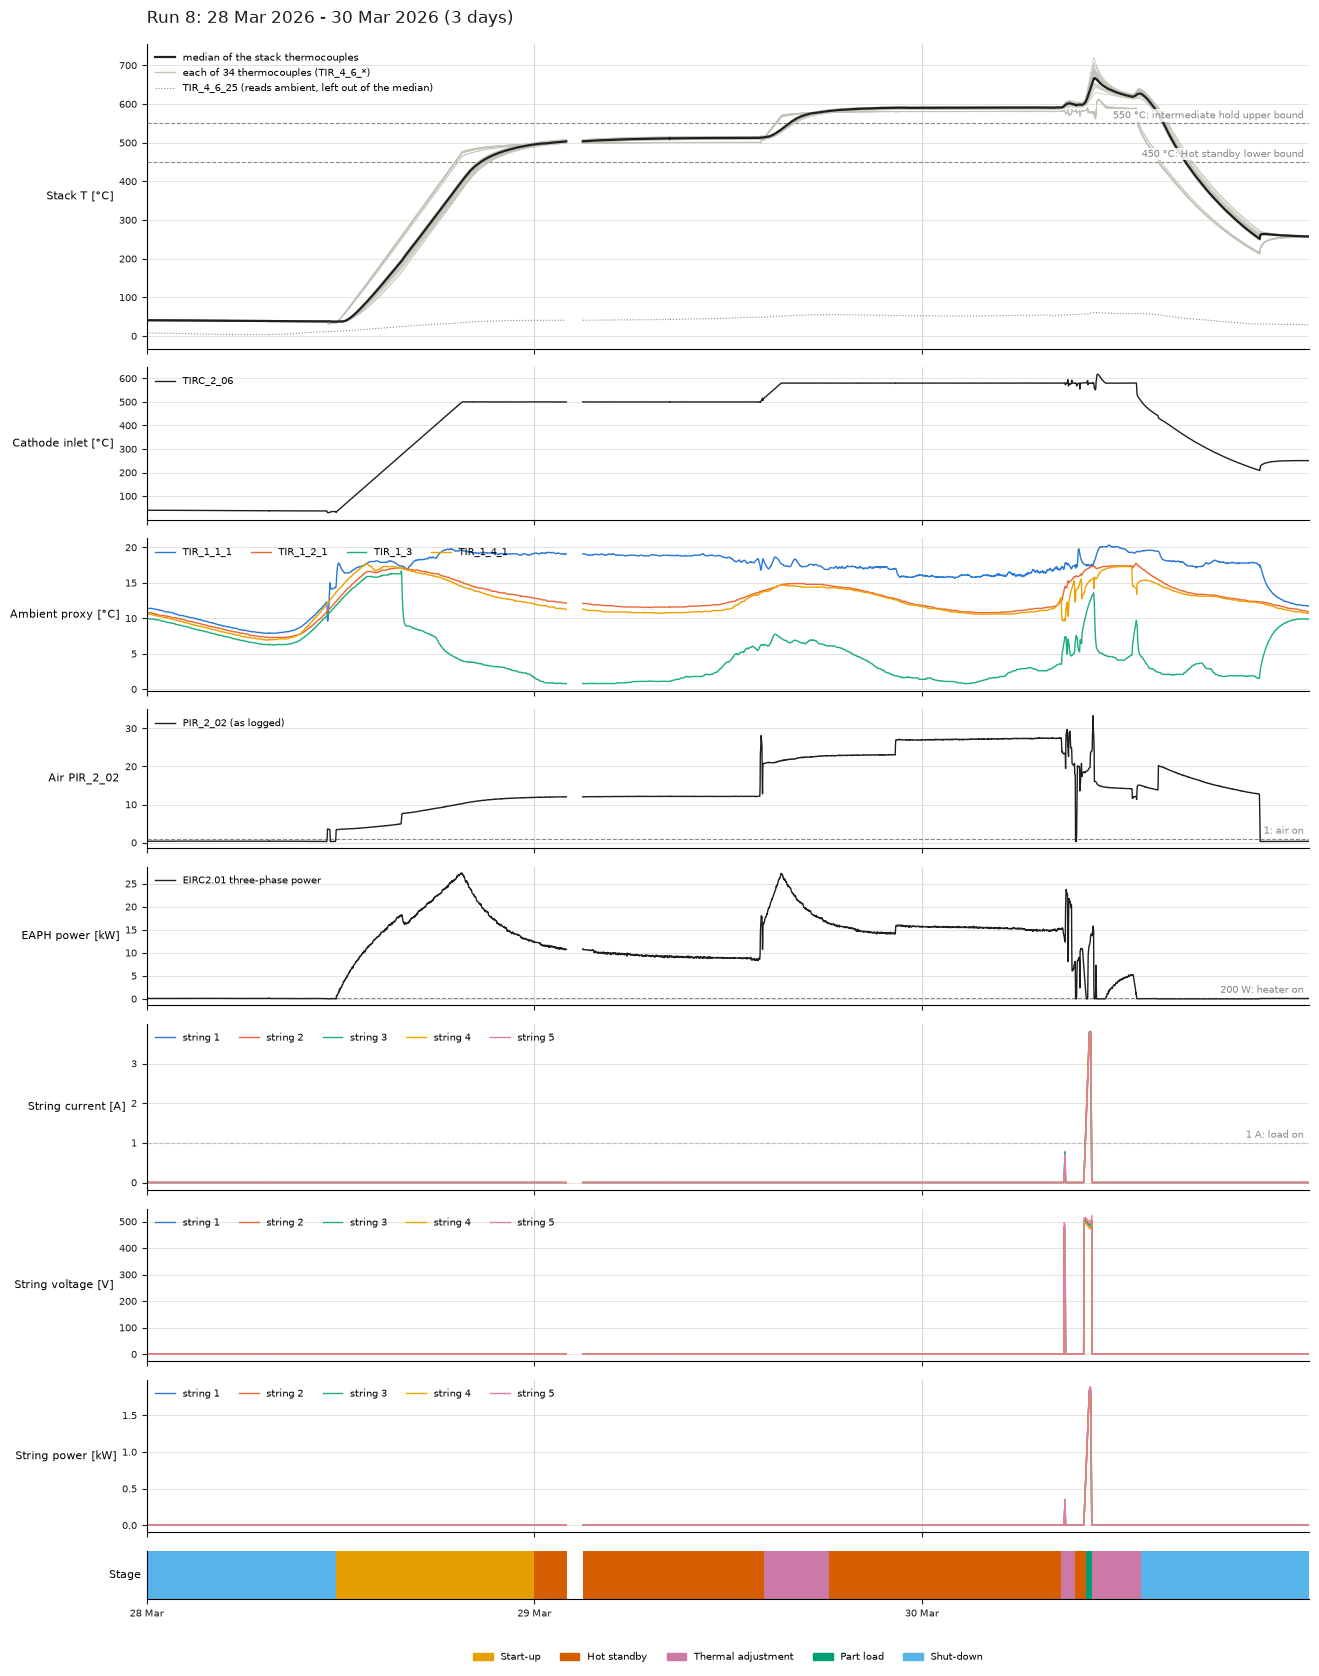

stage,Start-up,Hot standby,Thermal adjustment,Part load,Shut-down
hours,12.2,28.2,7.9,0.4,22.2


In [11]:
plot_run(8)


## Zoom into a window

Change the start and end to look closer at any part of a run (here 23 Mar 2026, 06:00–18:00: a start-up that reaches Hot standby. Part load occurs only on 13, 19, 24, 25 and 30 Mar).


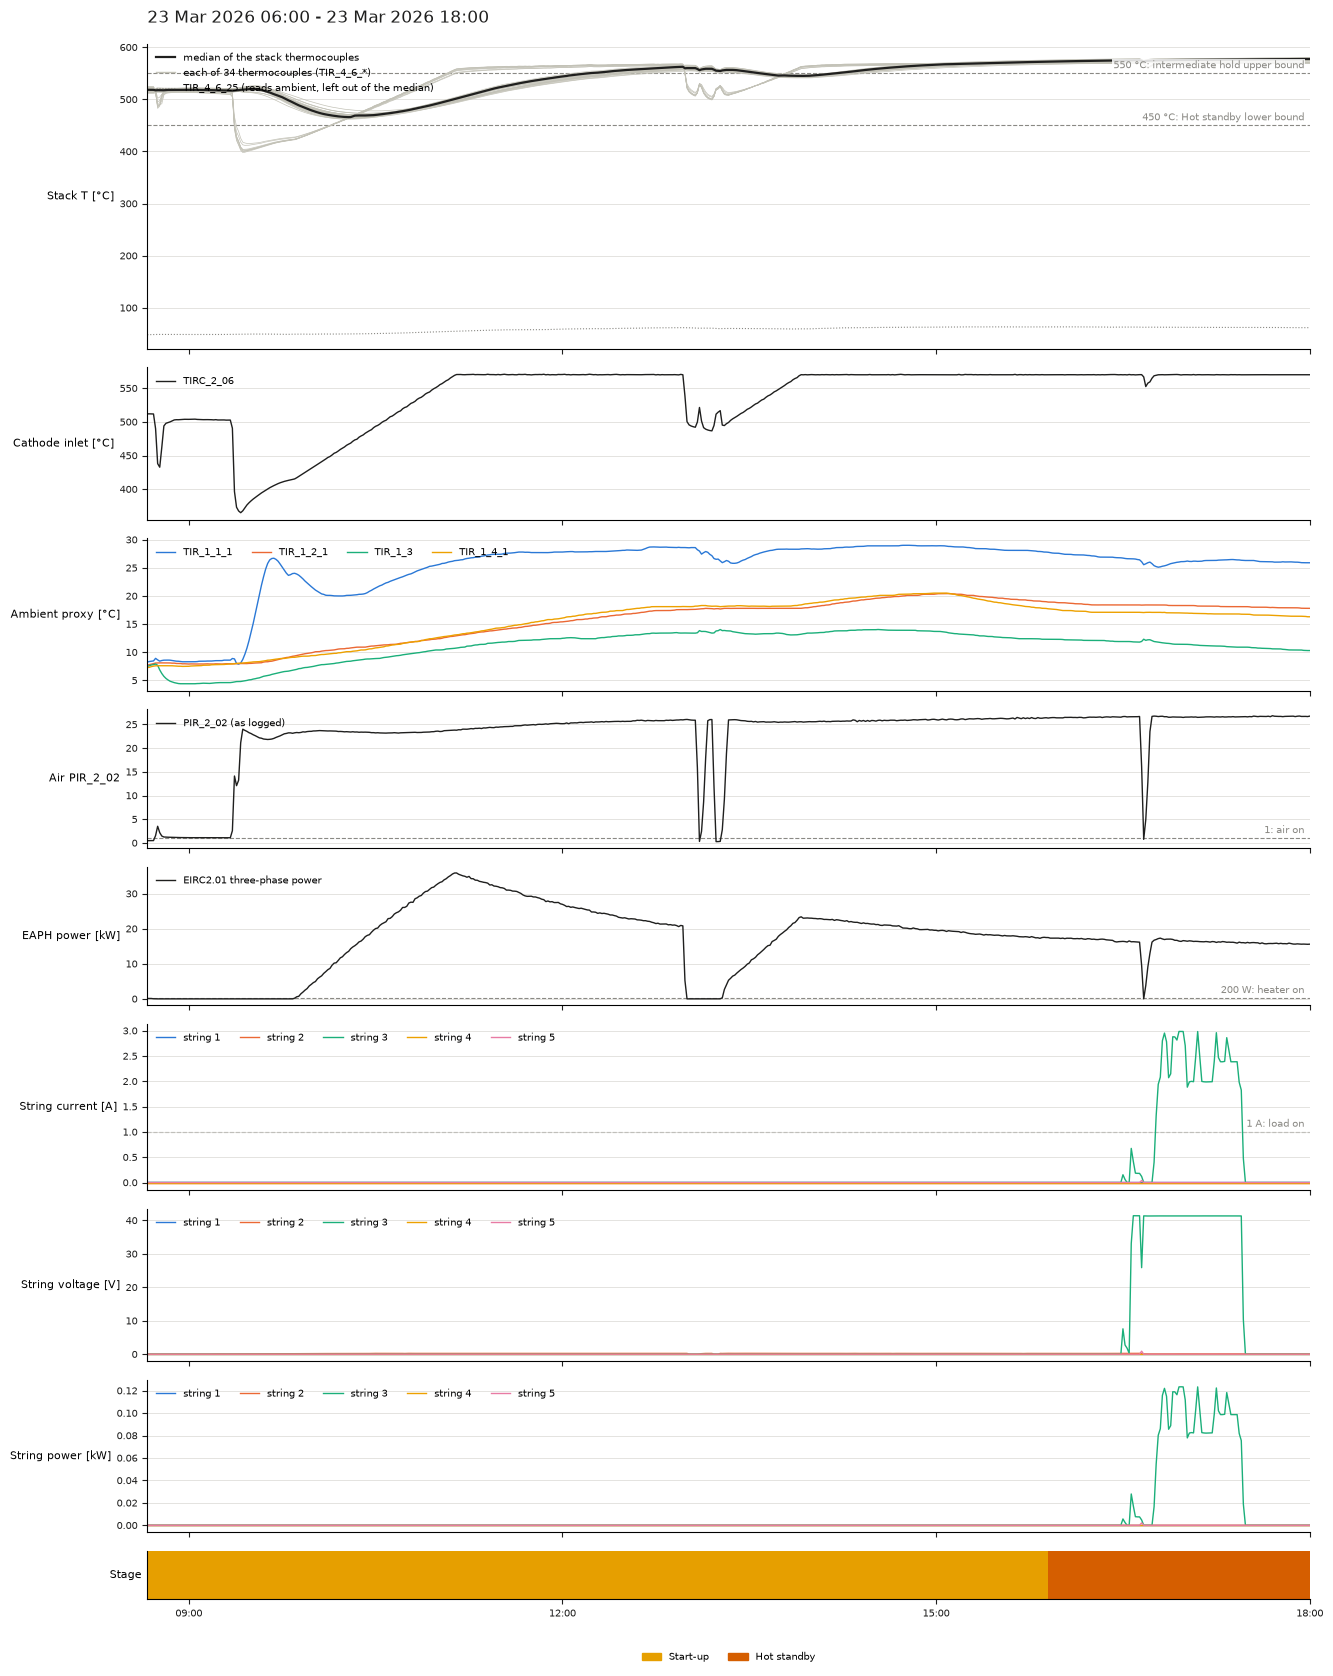

stage,Start-up,Hot standby
hours,7.2,2.1


In [12]:
plot_window("2026-03-23 06:00", "2026-03-23 18:00")